# nb02_preprocess : 전처리 및 hms-processed 생성 (M1)

- **가속기 : None (CPU)** · **인터넷 : 불필요**
- **입력** : 대회 데이터, Dataset `hms-src` (src/, configs/)
- **출력** : `/kaggle/working/hms_processed/` → 실행 후 이 Output으로 Dataset `hms-processed` 생성

| 섹션 | 내용 | 코드북 연결 |
|---|---|---|
| 0 | 설정, src 연결, 경로 자동 탐색 | 2-1 실행 구조 |
| 1 | 타깃 생성 + 정의 검증 | 4-2 타깃 변수 |
| 2 | 환자 단위 5-fold + 누수 검사 | 5 평가 체계 |
| 3 | eeg_id 대표 구간 선택 + 용량 확인 | 4-3 중복 처리 |
| 4 | 스모크 테스트 → 전체 생성 (50초 몽타주, 10분 스펙트로그램) | 4-3 전처리 |
| 5 | 결과 검증, 품질 요약, 저장 | 1단계 신호 품질 |

**실행 방법** : 먼저 `SMOKE = True`로 섹션 4까지 실행해 오류가 없는지 확인 → `SMOKE = False`로 바꾸고 Save Version(Save & Run All)

## 0. 설정 (목적 : src 연결과 경로 확정 / 입력 : hms-src / 출력 : CFG, DATA_DIR, OUT_DIR)

In [1]:
import sys, os, json, time
from pathlib import Path

# hms-src Dataset 위치 탐색 : /kaggle/input/hms-src 또는 하위 폴더 (zip 업로드 시 한 단계 더 생길 수 있음)
def find_src_root(root="/kaggle/input"):
    if os.environ.get("HMS_SRC_DIR"):
        return Path(os.environ["HMS_SRC_DIR"])
    for pattern in ["*/src/data/targets.py", "*/*/src/data/targets.py", "*/*/*/src/data/targets.py"]:
        hits = sorted(Path(root).glob(pattern))
        if hits:
            return hits[0].parents[2]
    raise FileNotFoundError("hms-src Dataset을 찾지 못했습니다. Add Input에서 hms-src를 연결하세요.")

SRC_ROOT = find_src_root()
sys.path.insert(0, str(SRC_ROOT))
print("SRC_ROOT :", SRC_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import load_config
from src.data.load import find_data_dir
from src.data.targets import build_targets, select_representative, aggregate_by_eeg, PROB_COLS, CLASSES
from src.data.folds import make_folds, check_no_leak
from src.data.build import build_dataset

CFG = load_config(SRC_ROOT / "configs" / "base.yaml")
DATA_DIR = find_data_dir()
OUT_DIR = Path(os.environ.get("HMS_OUT_DIR", "/kaggle/working")) / "hms_processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SMOKE = False            # True : 200개만 처리해 동작 확인 / False : 전체 처리
N_JOBS = os.cpu_count() or 4
HIGH_VOTE = CFG["labels"]["high_vote"]
print("DATA_DIR :", DATA_DIR, "| exists:", DATA_DIR.exists())
print("OUT_DIR  :", OUT_DIR, "| SMOKE:", SMOKE, "| N_JOBS:", N_JOBS)

SRC_ROOT : /kaggle/input/datasets/sungik4057/hms-src
DATA_DIR : /kaggle/input/competitions/hms-harmful-brain-activity-classification | exists: True
OUT_DIR  : /kaggle/working/hms_processed | SMOKE: False | N_JOBS: 4


## 1. 타깃 생성 (목적 : 투표→확률·축 정답·마스크 / 입력 : train.csv / 출력 : train)

In [2]:
raw = pd.read_csv(DATA_DIR / "train.csv")
train = build_targets(raw, high_vote=HIGH_VOTE, seizure_pos=CFG["labels"]["seizure_pos"])

# 정의 검증 : 전후 행 수 동일, 확률 합 1, 마스크 0이면 축 값 NaN
assert len(train) == len(raw)
assert np.allclose(train[PROB_COLS].sum(axis=1), 1)
assert train.loc[train.axis_mask == 0, ["axis_lat", "axis_pd"]].isna().all().all()

print(f"행 {len(train):,} | eeg_id {train.eeg_id.nunique():,} | 환자 {train.patient_id.nunique():,}")
print(f"고득표(>={HIGH_VOTE}) 비율 {train.high_vote.mean():.1%} | axis_mask=0 비율 {(train.axis_mask == 0).mean():.1%}")

행 106,800 | eeg_id 17,089 | 환자 1,950
고득표(>=10) 비율 37.4% | axis_mask=0 비율 25.3%


## 2. 환자 단위 5-fold (목적 : 환자 누수 방지 / 입력 : train / 출력 : fold 컬럼)

In [3]:
train = make_folds(train, n_folds=CFG["n_folds"], seed=CFG["seed"])
check_no_leak(train)
fold_tab = train.groupby("fold").agg(rows=("eeg_id", "size"), eeg_ids=("eeg_id", "nunique"),
                                     patients=("patient_id", "nunique"), high_vote=("high_vote", "mean"))
fold_tab["seizure_share"] = train.groupby("fold")["p_seizure"].mean()
display(fold_tab.round(3))

,rows,eeg_ids,patients,high_vote,seizure_share
fold,,,,,
0,21360,3345,389,0.365,0.190
1,21360,3389,389,0.409,0.241
2,21360,3461,390,0.372,0.205
3,21360,3277,391,0.396,0.213
4,21360,3617,391,0.328,0.192


## 3. eeg_id 대표 구간 선택 (목적 : 중복 구간 제거·저장 용량 확보 / 입력 : train / 출력 : meta)

In [4]:
meta = select_representative(train)
assert meta.eeg_id.is_unique and len(meta) == train.eeg_id.nunique()
check_no_leak(meta)

gb = len(meta) * (16 * 10000 + 4 * 100 * 300) * 2 / 1e9
print(f"대표 구간 {len(meta):,}개 (전체 {len(train):,}행 중) | 예상 용량 {gb:.1f} GB (한도 약 20GB)")
assert gb < 18, "용량 초과 위험 : 저장 범위를 줄여야 합니다"

dist = pd.DataFrame({
    "전체 구간": train.expert_consensus.str.lower().value_counts(normalize=True),
    "대표 구간": meta.expert_consensus.str.lower().value_counts(normalize=True),
}).reindex(CLASSES).round(3)
display(dist)  # 대표 구간 선택으로 클래스 분포가 크게 바뀌지 않았는지 확인

대표 구간 17,089개 (전체 106,800행 중) | 예상 용량 9.6 GB (한도 약 20GB)


,전체 구간,대표 구간
expert_consensus,,
seizure,0.196,0.154
lpd,0.139,0.152
gpd,0.156,0.106
lrda,0.156,0.055
grda,0.177,0.108
other,0.176,0.425


## 4. 배열 생성 (목적 : 50초 몽타주·10분 스펙트로그램 저장 / 입력 : meta / 출력 : eeg50.npy, spec10.npy, meta.csv)

In [5]:
run_meta = meta.sample(200, random_state=CFG["seed"]).reset_index(drop=True) if SMOKE else meta
t0 = time.time()
out = build_dataset(run_meta, DATA_DIR, OUT_DIR, n_jobs=N_JOBS, chunk=512,
                    fs=CFG["signal"]["fs"], band=tuple(CFG["signal"]["bandpass"]))
sec = time.time() - t0
print(f"{len(out):,}개 처리 {sec/60:.1f}분 | 개당 {sec/len(out)*1000:.0f} ms | 전체 예상 {sec/len(out)*len(meta)/60:.0f}분")

  512/17,089 (3%) | 28s
  1,024/17,089 (6%) | 48s
  1,536/17,089 (9%) | 67s
  2,048/17,089 (12%) | 86s
  2,560/17,089 (15%) | 106s
  3,072/17,089 (18%) | 124s
  3,584/17,089 (21%) | 142s
  4,096/17,089 (24%) | 161s
  4,608/17,089 (27%) | 180s
  5,120/17,089 (30%) | 197s
  5,632/17,089 (33%) | 214s
  6,144/17,089 (36%) | 230s
  6,656/17,089 (39%) | 247s
  7,168/17,089 (42%) | 264s
  7,680/17,089 (45%) | 279s
  8,192/17,089 (48%) | 295s
  8,704/17,089 (51%) | 311s
  9,216/17,089 (54%) | 328s
  9,728/17,089 (57%) | 343s
  10,240/17,089 (60%) | 359s
  10,752/17,089 (63%) | 377s
  11,264/17,089 (66%) | 395s
  11,776/17,089 (69%) | 415s
  12,288/17,089 (72%) | 434s
  12,800/17,089 (75%) | 454s
  13,312/17,089 (78%) | 473s
  13,824/17,089 (81%) | 492s
  14,336/17,089 (84%) | 509s
  14,848/17,089 (87%) | 527s
  15,360/17,089 (90%) | 545s
  15,872/17,089 (93%) | 562s
  16,384/17,089 (96%) | 579s
  16,896/17,089 (99%) | 598s
  17,089/17,089 (100%) | 605s
17,089개 처리 10.1분 | 개당 36 ms | 전체 예상 10분


## 5. 결과 검증 및 저장 (목적 : 배열·품질 확인 / 출력 : train_all.csv, config_used.json)

In [6]:
eeg = np.load(OUT_DIR / "eeg50.npy", mmap_mode="r")
spec = np.load(OUT_DIR / "spec10.npy", mmap_mode="r")
print("eeg50 :", eeg.shape, eeg.dtype, "| spec10 :", spec.shape, spec.dtype)
assert eeg.shape[0] == spec.shape[0] == len(out)

idx = np.random.default_rng(0).choice(len(out), size=min(200, len(out)), replace=False)
assert np.isfinite(eeg[idx].astype(np.float32)).all() and np.isfinite(spec[idx].astype(np.float32)).all()

print(f"품질 플래그 비율 {out.qc_flag.mean():.1%} | 결측 있는 구간 {(out.nan_ratio > 0).mean():.1%} | "
      f"평탄 채널 있는 구간 {(out.n_flat > 0).mean():.1%}")
display(out[["nan_ratio", "n_flat", "max_abs"]].describe().round(2))

train.to_csv(OUT_DIR / "train_all.csv", index=False)   # 전체 구간 (분석·평가용)
with open(OUT_DIR / "config_used.json", "w") as f:
    json.dump({**CFG, "smoke": SMOKE, "n_rows": len(out),
               "representative_rule": "max n_votes, tie -> nearest to median offset"}, f, indent=2)
print("저장 파일 :", sorted(p.name for p in OUT_DIR.iterdir()))

eeg50 : (17089, 16, 10000) float16 | spec10 : (17089, 4, 100, 300) float16
품질 플래그 비율 26.1% | 결측 있는 구간 3.4% | 평탄 채널 있는 구간 0.0%


,nan_ratio,n_flat,max_abs
count,17089.00,17089.00,17089.00
mean,0.00,0.00,3023.88
std,0.02,0.12,9422.81
min,0.00,0.00,0.00
25%,0.00,0.00,147.28
50%,0.00,0.00,328.19
75%,0.00,0.00,1062.95
max,0.52,16.00,67373.06


저장 파일 : ['config_used.json', 'eeg50.npy', 'meta.csv', 'spec10.npy', 'train_all.csv']


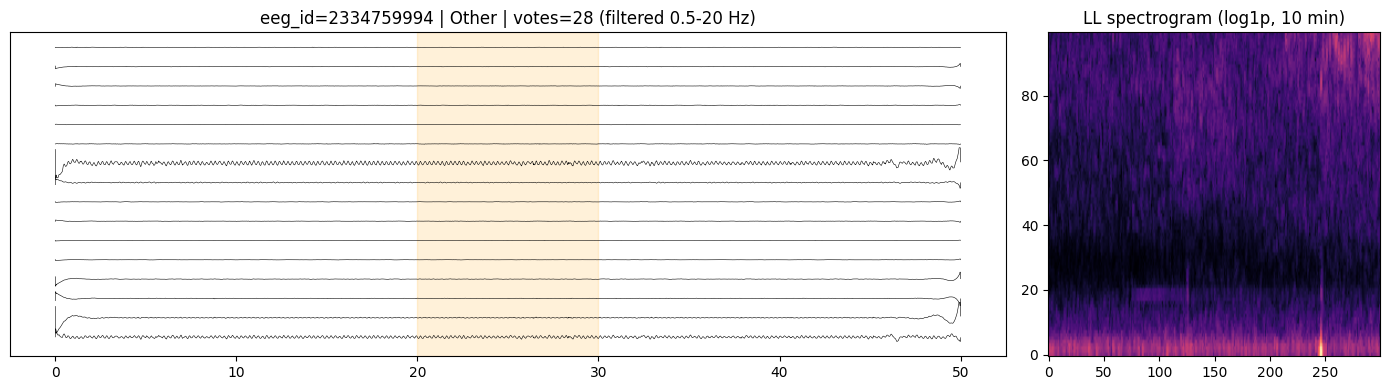

In [7]:
# 육안 점검 : 대표 구간 1건의 몽타주 신호와 스펙트로그램
i = int(np.argmax(out.n_votes.values))
r = out.iloc[i]
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
x = eeg[i].astype(np.float32)
for c in range(16):
    ax[0].plot(np.arange(x.shape[1]) / 200, x[c] / (np.abs(x).max() + 1e-6) * 2 - c * 2.5, lw=0.4, color="k")
ax[0].axvspan(20, 30, color="orange", alpha=0.15)
ax[0].set_title(f"eeg_id={r.eeg_id} | {r.expert_consensus} | votes={int(r.n_votes)} (filtered 0.5-20 Hz)")
ax[0].set_yticks([])
ax[1].imshow(spec[i, 0].astype(np.float32), aspect="auto", origin="lower", cmap="magma")
ax[1].set_title("LL spectrogram (log1p, 10 min)")
plt.tight_layout(); plt.show()

## 다음 단계
1. `SMOKE = True` 결과 확인 : 섹션 4의 **전체 예상 시간**을 확인 (Kaggle 세션 12시간 이내인지)
2. `SMOKE = False`로 바꾸고 **Save Version → Save & Run All**
3. 완료된 버전의 Output 화면에서 **New Dataset** → 이름 `hms-processed`
4. 결과 공유 : 섹션 1·2·3·5 출력 (fold 표, 클래스 분포 표, 품질 요약)